In [7]:

!pip install -q datasets transformers accelerate gensim gradio seaborn scikit-learn

import os
import re
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from datasets import load_dataset
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)

# تثبيت البذور العشوائية لضمان تكرارية النتائج
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Active Compute Device: {device}")


raw_goemotions = load_dataset("google-research-datasets/go_emotions", "simplified")
orig_label_names = raw_goemotions["train"].features["labels"].feature.names

EKMAN_MAPPING = {
    "joy": ["joy", "amusement", "approval", "excitement", "gratitude", "love", "optimism", "relief", "pride", "admiration", "desire", "caring"],
    "sadness": ["sadness", "disappointment", "embarrassment", "grief", "remorse"],
    "anger": ["anger", "annoyance", "disapproval"],
    "fear": ["fear", "nervousness"],
    "surprise": ["surprise", "realization", "confusion", "curiosity"],
    "disgust": ["disgust"]
}

fine_to_ekman = {}
for ekman_emo, fine_list in EKMAN_MAPPING.items():
    for fine_emo in fine_list:
        fine_to_ekman[fine_emo] = ekman_emo

TARGET_CLASSES = ["joy", "sadness", "anger", "fear", "surprise", "disgust"]
label2id = {lbl: idx for idx, lbl in enumerate(TARGET_CLASSES)}
id2label = {idx: lbl for idx, lbl in enumerate(TARGET_CLASSES)}
NUM_CLASSES = len(TARGET_CLASSES)

def map_to_six_emotions(split_ds):
    texts, labels = [], []
    for text, lbl_ids in zip(split_ds["text"], split_ds["labels"]):
   
        mapped_emos = {fine_to_ekman[orig_label_names[i]] for i in lbl_ids if orig_label_names[i] in fine_to_ekman}
        if len(mapped_emos) == 1:
            emo = list(mapped_emos)[0]
            texts.append(text)
            labels.append(label2id[emo])
    return pd.DataFrame({"text": texts, "label": labels, "emotion": [id2label[l] for l in labels]})

train_df = map_to_six_emotions(raw_goemotions["train"])
val_df   = map_to_six_emotions(raw_goemotions["validation"])
test_df  = map_to_six_emotions(raw_goemotions["test"])

print(f"\nMapped Dataset Shapes -> Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
print("\nClass Distribution in Training Set:")
print(train_df["emotion"].value_counts())


class_weights_np = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(NUM_CLASSES),
    y=train_df["label"].values
)
class_weights_tensor = torch.tensor(class_weights_np, dtype=torch.float32).to(device)
print("\nComputed Balanced Class Weights:", {id2label[i]: round(w, 2) for i, w in enumerate(class_weights_np)})

Active Compute Device: cuda

Mapped Dataset Shapes -> Train: 28104 | Val: 3527 | Test: 3539

Class Distribution in Training Set:
emotion
joy         15809
anger        4590
surprise     4160
sadness      2455
fear          566
disgust       524
Name: count, dtype: int64

Computed Balanced Class Weights: {'joy': np.float64(0.3), 'sadness': np.float64(1.91), 'anger': np.float64(1.02), 'fear': np.float64(8.28), 'surprise': np.float64(1.13), 'disgust': np.float64(8.94)}


In [8]:
import gensim.downloader as api
from collections import Counter

def tokenize_emotion_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"\[name\]|\[religion\]", " ", text)
    text = re.sub(r"([!?.,'\"()])", r" \1 ", text)
    text = re.sub(r"[^a-z0-9!?.,'\"()\s]", " ", text)
    tokens = text.split()
    return tokens if tokens else ["<unk>"]

train_tokens = [tokenize_emotion_text(t) for t in train_df["text"]]
val_tokens   = [tokenize_emotion_text(t) for t in val_df["text"]]
test_tokens  = [tokenize_emotion_text(t) for t in test_df["text"]]

print("Loading FastText 300d (fasttext-wiki-news-subwords-300)...")
ft_vectors = api.load("fasttext-wiki-news-subwords-300")
EMBEDDING_DIM = 300

word2idx = {"<PAD>": 0, "<UNK>": 1}
word_counts = Counter(tok for seq in train_tokens for tok in seq)

for tok, count in word_counts.items():
    if count >= 2 or tok in ft_vectors:
        if tok not in word2idx:
            word2idx[tok] = len(word2idx)

for seq in val_tokens + test_tokens:
    for tok in seq:
        if tok not in word2idx and tok in ft_vectors:
            word2idx[tok] = len(word2idx)

VOCAB_SIZE = len(word2idx)
embedding_matrix = np.random.normal(scale=0.05, size=(VOCAB_SIZE, EMBEDDING_DIM)).astype("float32")
embedding_matrix[0] = np.zeros(EMBEDDING_DIM)

ft_hits = 0
for word, idx in word2idx.items():
    if word in ft_vectors:
        embedding_matrix[idx] = ft_vectors[word]
        ft_hits += 1

print(f"Vocabulary Size: {VOCAB_SIZE:,} | FastText 300d Coverage: {ft_hits:,}/{VOCAB_SIZE:,} ({ft_hits/VOCAB_SIZE*100:.1f}%)")

MAX_LEN = 48

def encode_and_pad(token_lists, max_len=MAX_LEN):
    encoded = np.zeros((len(token_lists), max_len), dtype=np.int64)
    lengths = np.zeros(len(token_lists), dtype=np.int64)
    for i, seq in enumerate(token_lists):
        trunc = seq[:max_len]
        lengths[i] = max(1, len(trunc))
        ids = [word2idx.get(tok, 1) for tok in trunc]
        encoded[i, :len(ids)] = ids
    return encoded, lengths

X_train, len_train = encode_and_pad(train_tokens)
X_val, len_val     = encode_and_pad(val_tokens)
X_test, len_test   = encode_and_pad(test_tokens)

y_train = train_df["label"].values
y_val   = val_df["label"].values
y_test  = test_df["label"].values

smoothed_weights_np = np.power(class_weights_np, 0.45)
smoothed_weights_np = smoothed_weights_np / smoothed_weights_np.mean()
class_weights_tensor = torch.tensor(smoothed_weights_np, dtype=torch.float32).to(device)
print("Smoothed Class Weights:", {id2label[i]: round(float(w), 2) for i, w in enumerate(smoothed_weights_np)})

class EmotionDataset(Dataset):
    def __init__(self, X, lengths, y):
        self.X = torch.tensor(X, dtype=torch.long)
        self.lengths = torch.tensor(lengths, dtype=torch.long)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.lengths[idx], self.y[idx]

BATCH_SIZE = 64
train_loader = DataLoader(EmotionDataset(X_train, len_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(EmotionDataset(X_val, len_val, y_val), batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(EmotionDataset(X_test, len_test, y_test), batch_size=BATCH_SIZE, shuffle=False)

Loading FastText 300d (fasttext-wiki-news-subwords-300)...
Vocabulary Size: 20,228 | FastText 300d Coverage: 20,063/20,228 (99.2%)
Smoothed Class Weights: {'joy': 0.38, 'sadness': 0.87, 'anger': 0.65, 'fear': 1.68, 'surprise': 0.68, 'disgust': 1.74}


In [9]:
class SpatialDropout(nn.Module):
    def __init__(self, drop_prob):
        super().__init__()
        self.drop = nn.Dropout2d(drop_prob)

    def forward(self, x):
        x = x.permute(0, 2, 1).unsqueeze(-1)
        x = self.drop(x)
        return x.squeeze(-1).permute(0, 2, 1)

class AdditiveAttention(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()
        self.attn = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.Tanh(),
            nn.Linear(hidden_dim // 2, 1, bias=False)
        )

    def forward(self, hidden_states, mask):
        scores = self.attn(hidden_states).squeeze(-1)
        scores = scores.masked_fill(~mask, -1e9)
        weights = torch.softmax(scores, dim=-1)
        context = torch.bmm(weights.unsqueeze(1), hidden_states).squeeze(1)
        return context, weights

class EmotionSequenceClassifier(nn.Module):
    def __init__(self, vocab_size, emb_matrix, num_classes, rnn_type="LSTM", hidden_dim=256, bidirectional=False, use_attention=False):
        super().__init__()
        self.rnn_type = rnn_type
        self.bidirectional = bidirectional
        self.use_attention = use_attention

        self.embedding = nn.Embedding.from_pretrained(torch.tensor(emb_matrix), freeze=False, padding_idx=0)
        self.spatial_drop = SpatialDropout(0.35)

        rnn_cls = nn.LSTM if rnn_type == "LSTM" else nn.GRU
        self.rnn = rnn_cls(
            input_size=emb_matrix.shape[1],
            hidden_size=hidden_dim,
            num_layers=2,
            batch_first=True,
            bidirectional=bidirectional,
            dropout=0.35
        )

        out_dim = hidden_dim * (2 if bidirectional else 1)
        if self.use_attention:
            self.attention = AdditiveAttention(out_dim)
            cls_in_dim = out_dim * 2
        else:
            cls_in_dim = out_dim

        self.classifier = nn.Sequential(
            nn.LayerNorm(cls_in_dim),
            nn.Dropout(0.45),
            nn.Linear(cls_in_dim, 160),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(160, num_classes)
        )

    def forward(self, x, lengths):
        mask = (x != 0)
        emb = self.spatial_drop(self.embedding(x))

        packed = nn.utils.rnn.pack_padded_sequence(emb, lengths.cpu(), batch_first=True, enforce_sorted=False)
        packed_out, hidden = self.rnn(packed)
        rnn_out, _ = nn.utils.rnn.pad_packed_sequence(packed_out, batch_first=True, total_length=x.size(1))

        if self.use_attention:
            attn_ctx, attn_weights = self.attention(rnn_out, mask)
            masked_out = rnn_out.masked_fill(~mask.unsqueeze(-1), -1e9)
            max_pool, _ = torch.max(masked_out, dim=1)
            rep = torch.cat([attn_ctx, max_pool], dim=-1)
        else:
            attn_weights = None
            h_n = hidden[0] if self.rnn_type == "LSTM" else hidden
            if self.bidirectional:
                rep = torch.cat((h_n[-2], h_n[-1]), dim=-1)
            else:
                rep = h_n[-1]

        logits = self.classifier(rep)
        return logits, attn_weights

def evaluate_seq_model(model, loader):
    model.eval()
    all_preds, all_trues = [], []
    with torch.no_grad():
        for x, lengths, y in loader:
            x, lengths = x.to(device), lengths.to(device)
            logits, _ = model(x, lengths)
            preds = torch.argmax(logits, dim=-1).cpu().tolist()
            all_preds.extend(preds)
            all_trues.extend(y.tolist())
    acc = accuracy_score(all_trues, all_preds)
    macro_f1 = f1_score(all_trues, all_preds, average="macro")
    report = classification_report(all_trues, all_preds, target_names=TARGET_CLASSES, output_dict=True, zero_division=0)
    cm = confusion_matrix(all_trues, all_preds)
    return acc, macro_f1, report, cm, all_trues, all_preds

def train_seq_model(model, name, epochs=10, lr=1e-3):
    model.to(device)
    criterion = nn.CrossEntropyLoss(weight=class_weights_tensor, label_smoothing=0.05)
    emb_params = list(model.embedding.parameters())
    other_params = [p for n, p in model.named_parameters() if not n.startswith("embedding.")]
    optimizer = optim.AdamW([
        {"params": other_params, "lr": lr, "weight_decay": 1e-2},
        {"params": emb_params, "lr": lr * 0.25, "weight_decay": 1e-4}
    ])
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-5)

    best_val_score, best_state = 0.0, None
    print(f"\n{'='*55}\nTraining {name} (FastText 300d + Smoothed Weights)...\n{'='*55}")
    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        for x, lengths, y in train_loader:
            x, lengths, y = x.to(device), lengths.to(device), y.to(device)
            optimizer.zero_grad()
            logits, _ = model(x, lengths)
            loss = criterion(logits, y)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=3.0)
            optimizer.step()
            total_loss += loss.item()
        scheduler.step()

        val_acc, val_f1, _, _, _, _ = evaluate_seq_model(model, val_loader)
        combined_metric = 0.5 * val_acc + 0.5 * val_f1
        print(f"Epoch {epoch:02d}/{epochs} | Loss: {total_loss/len(train_loader):.4f} | Val Acc: {val_acc:.4f} | Val Macro F1: {val_f1:.4f}")
        if combined_metric > best_val_score:
            best_val_score = combined_metric
            best_state = {k: v.cpu() for k, v in model.state_dict().items()}

    model.load_state_dict({k: v.to(device) for k, v in best_state.items()})
    test_acc, test_f1, test_report, test_cm, trues, preds = evaluate_seq_model(model, test_loader)
    print(f">>> {name} Test Results -> Accuracy: {test_acc:.4f} | Macro F1: {test_f1:.4f}")
    return model, {
        "Model": name,
        "Accuracy": test_acc,
        "Macro F1": test_f1,
        "Report": test_report,
        "CM": test_cm,
        "Trues": trues,
        "Preds": preds
    }

emotion_benchmarks = {}
trained_emotion_models = {}

configs = [
    ("LSTM", "LSTM", False, False),
    ("GRU", "GRU", False, False),
    ("BiLSTM + Attention", "LSTM", True, True)
]

for name, r_type, bidir, attn in configs:
    m = EmotionSequenceClassifier(VOCAB_SIZE, embedding_matrix, NUM_CLASSES, rnn_type=r_type, hidden_dim=256, bidirectional=bidir, use_attention=attn)
    trained_emotion_models[name], emotion_benchmarks[name] = train_seq_model(m, name, epochs=10, lr=1e-3)


Training LSTM (FastText 300d + Smoothed Weights)...
Epoch 01/10 | Loss: 1.4859 | Val Acc: 0.7048 | Val Macro F1: 0.4162
Epoch 02/10 | Loss: 1.2260 | Val Acc: 0.7445 | Val Macro F1: 0.5325
Epoch 03/10 | Loss: 1.0594 | Val Acc: 0.7686 | Val Macro F1: 0.6407
Epoch 04/10 | Loss: 0.9483 | Val Acc: 0.7664 | Val Macro F1: 0.6532
Epoch 05/10 | Loss: 0.8664 | Val Acc: 0.7624 | Val Macro F1: 0.6653
Epoch 06/10 | Loss: 0.8022 | Val Acc: 0.7667 | Val Macro F1: 0.6531
Epoch 07/10 | Loss: 0.7573 | Val Acc: 0.7618 | Val Macro F1: 0.6441
Epoch 08/10 | Loss: 0.7208 | Val Acc: 0.7582 | Val Macro F1: 0.6369
Epoch 09/10 | Loss: 0.7000 | Val Acc: 0.7582 | Val Macro F1: 0.6351
Epoch 10/10 | Loss: 0.6834 | Val Acc: 0.7601 | Val Macro F1: 0.6434
>>> LSTM Test Results -> Accuracy: 0.7539 | Macro F1: 0.6618

Training GRU (FastText 300d + Smoothed Weights)...
Epoch 01/10 | Loss: 1.4567 | Val Acc: 0.7196 | Val Macro F1: 0.4511
Epoch 02/10 | Loss: 1.1336 | Val Acc: 0.7743 | Val Macro F1: 0.6564
Epoch 03/10 | Loss

In [11]:
from datasets import Dataset as HFDataset

MODEL_NAME = "distilbert-base-uncased"
bert_tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_for_bert(batch):
    return bert_tokenizer(batch["text"], truncation=True, max_length=64)

hf_train = HFDataset.from_pandas(train_df[["text", "label"]]).map(tokenize_for_bert, batched=True)
hf_val   = HFDataset.from_pandas(val_df[["text", "label"]]).map(tokenize_for_bert, batched=True)
hf_test  = HFDataset.from_pandas(test_df[["text", "label"]]).map(tokenize_for_bert, batched=True)

data_collator = DataCollatorWithPadding(tokenizer=bert_tokenizer)

def compute_hf_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    acc = accuracy_score(labels, preds)
    macro_f1 = f1_score(labels, preds, average="macro")
    return {"accuracy": acc, "macro_f1": macro_f1}

class WeightedEmotionTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.get("logits")
        loss_fct = nn.CrossEntropyLoss(weight=class_weights_tensor, label_smoothing=0.05)
        loss = loss_fct(logits.view(-1, self.model.config.num_labels), labels.view(-1))
        return (loss, outputs) if return_outputs else loss

distilbert_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_CLASSES,
    id2label=id2label,
    label2id=label2id,
    attn_implementation="eager"
)

total_steps = (len(hf_train) // 32) * 4
warmup_steps = int(total_steps * 0.1)

training_args = TrainingArguments(
    output_dir="./distilbert_emotion_checkpoints",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2.5e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    num_train_epochs=4,
    weight_decay=0.01,
    warmup_steps=warmup_steps,
    fp16=torch.cuda.is_available(),
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    logging_steps=200,
    report_to="none"
)

trainer = WeightedEmotionTrainer(
    model=distilbert_model,
    args=training_args,
    train_dataset=hf_train,
    eval_dataset=hf_val,
    processing_class=bert_tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_hf_metrics
)

print("Fine-Tuning DistilBERT with HuggingFace Trainer API...")
trainer.train()

test_predictions = trainer.predict(hf_test)
bert_preds = np.argmax(test_predictions.predictions, axis=-1)
bert_trues = test_df["label"].values

bert_acc = accuracy_score(bert_trues, bert_preds)
bert_f1  = f1_score(bert_trues, bert_preds, average="macro")
bert_report = classification_report(bert_trues, bert_preds, target_names=TARGET_CLASSES, output_dict=True, zero_division=0)
bert_cm = confusion_matrix(bert_trues, bert_preds)

emotion_benchmarks["DistilBERT (Fine-Tuned)"] = {
    "Model": "DistilBERT (Fine-Tuned)",
    "Accuracy": bert_acc,
    "Macro F1": bert_f1,
    "Report": bert_report,
    "CM": bert_cm,
    "Trues": bert_trues.tolist(),
    "Preds": bert_preds.tolist()
}

print(f"\n>>> Fine-Tuned DistilBERT Test Results -> Accuracy: {bert_acc:.4f} | Macro F1: {bert_f1:.4f}")

Map:   0%|          | 0/28104 [00:00<?, ? examples/s]

Map:   0%|          | 0/3527 [00:00<?, ? examples/s]

Map:   0%|          | 0/3539 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Fine-Tuning DistilBERT with HuggingFace Trainer API...


... (2 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


>>> Fine-Tuned DistilBERT Test Results -> Accuracy: 0.8194 | Macro F1: 0.7226



OVERALL ARCHITECTURE BENCHMARK (GoEmotions 6-Class Test Set)
           Architecture Test Accuracy Macro F1-Score
                   LSTM        75.39%         0.6618
                    GRU        76.80%         0.6619
     BiLSTM + Attention        77.59%         0.6795
DistilBERT (Fine-Tuned)        81.94%         0.7226

PER-CLASS METRICS — FINE-TUNED DISTILBERT (TEST SET)
Emotion Class Precision Recall F1-Score  Support
          JOY    0.9183 0.8993   0.9087     1937
      SADNESS    0.7235 0.6409   0.6797      298
        ANGER    0.6811 0.7471   0.7126      609
         FEAR    0.6735 0.7765   0.7213       85
     SURPRISE    0.7533 0.7561   0.7547      533
      DISGUST    0.5584 0.5584   0.5584       77


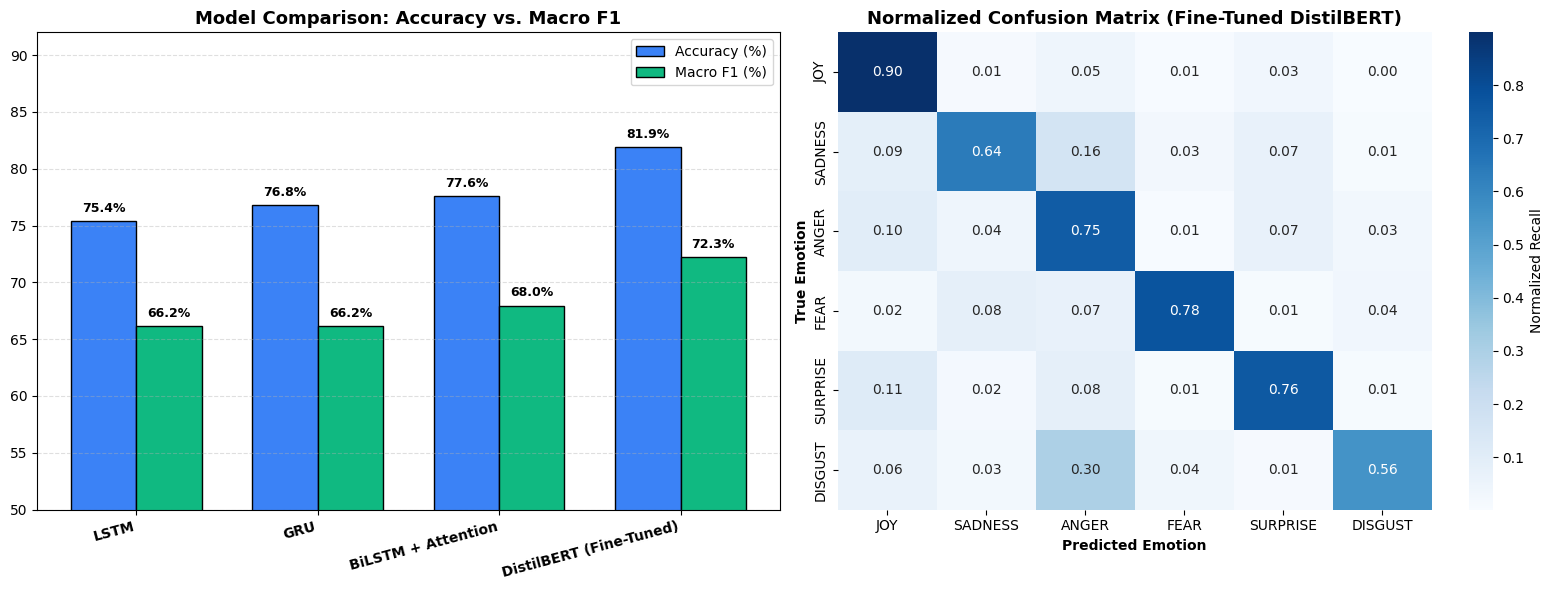

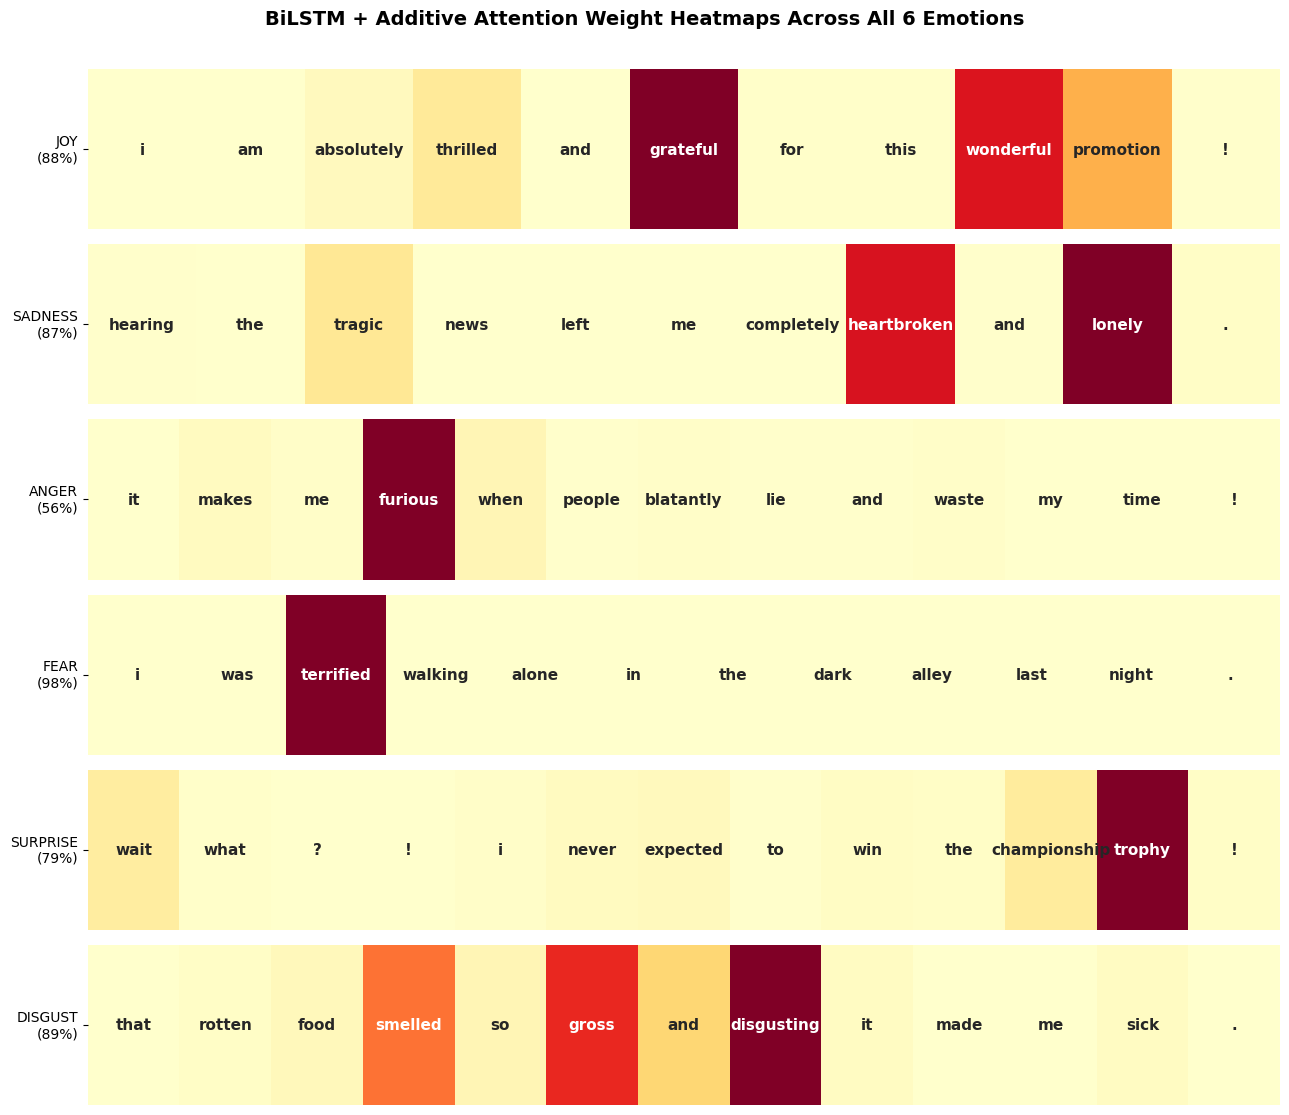

In [12]:
summary_rows = []
for name, res in emotion_benchmarks.items():
    summary_rows.append({
        "Architecture": name,
        "Test Accuracy": f"{res['Accuracy']*100:.2f}%",
        "Macro F1-Score": f"{res['Macro F1']:.4f}"
    })

summary_df = pd.DataFrame(summary_rows)
print("\n" + "="*65)
print("OVERALL ARCHITECTURE BENCHMARK (GoEmotions 6-Class Test Set)")
print("="*65)
print(summary_df.to_string(index=False))

best_report = emotion_benchmarks["DistilBERT (Fine-Tuned)"]["Report"]
per_class_rows = []
for emo in TARGET_CLASSES:
    per_class_rows.append({
        "Emotion Class": emo.upper(),
        "Precision": f"{best_report[emo]['precision']:.4f}",
        "Recall": f"{best_report[emo]['recall']:.4f}",
        "F1-Score": f"{best_report[emo]['f1-score']:.4f}",
        "Support": int(best_report[emo]['support'])
    })

per_class_df = pd.DataFrame(per_class_rows)
print("\n" + "="*65)
print("PER-CLASS METRICS — FINE-TUNED DISTILBERT (TEST SET)")
print("="*65)
print(per_class_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

models_list = [r["Architecture"] for r in summary_rows]
accs = [emotion_benchmarks[m]["Accuracy"] * 100 for m in models_list]
f1s  = [emotion_benchmarks[m]["Macro F1"] * 100 for m in models_list]

x_pos = np.arange(len(models_list))
width = 0.36
bars1 = axes[0].bar(x_pos - width/2, accs, width, label="Accuracy (%)", color="#3b82f6", edgecolor="black")
bars2 = axes[0].bar(x_pos + width/2, f1s, width, label="Macro F1 (%)", color="#10b981", edgecolor="black")

axes[0].set_title("Model Comparison: Accuracy vs. Macro F1", fontsize=13, fontweight="bold")
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(models_list, rotation=15, ha="right", fontweight="bold")
axes[0].set_ylim(50, 92)
axes[0].grid(axis="y", linestyle="--", alpha=0.4)
axes[0].legend()

for b in bars1:
    axes[0].text(b.get_x() + b.get_width()/2, b.get_height() + 0.8, f"{b.get_height():.1f}%", ha="center", fontsize=9, fontweight="bold")
for b in bars2:
    axes[0].text(b.get_x() + b.get_width()/2, b.get_height() + 0.8, f"{b.get_height():.1f}%", ha="center", fontsize=9, fontweight="bold")

cm_norm = emotion_benchmarks["DistilBERT (Fine-Tuned)"]["CM"].astype("float")
cm_norm = cm_norm / cm_norm.sum(axis=1)[:, np.newaxis]

sns.heatmap(
    cm_norm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=[e.upper() for e in TARGET_CLASSES],
    yticklabels=[e.upper() for e in TARGET_CLASSES],
    ax=axes[1],
    cbar_kws={"label": "Normalized Recall"}
)
axes[1].set_title("Normalized Confusion Matrix (Fine-Tuned DistilBERT)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Predicted Emotion", fontweight="bold")
axes[1].set_ylabel("True Emotion", fontweight="bold")

plt.tight_layout()
plt.savefig("emotion_benchmark_and_cm.png", dpi=300)
plt.show()

attn_model = trained_emotion_models["BiLSTM + Attention"]
attn_model.eval()

def get_bilstm_attention(sentence):
    tokens = tokenize_emotion_text(sentence)[:MAX_LEN]
    ids = [word2idx.get(tok, 1) for tok in tokens]
    padded = ids + [0] * (MAX_LEN - len(ids))
    x_tensor = torch.tensor([padded], dtype=torch.long).to(device)
    len_tensor = torch.tensor([len(ids)], dtype=torch.long).to(device)
    with torch.no_grad():
        logits, weights = attn_model(x_tensor, len_tensor)
        probs = torch.softmax(logits, dim=-1)[0].cpu().numpy()
        pred_idx = int(np.argmax(probs))
        attn_scores = weights[0, :len(ids)].cpu().numpy()
    return tokens, attn_scores, id2label[pred_idx], probs[pred_idx]

sample_sentences = [
    "I am absolutely thrilled and grateful for this wonderful promotion!",
    "Hearing the tragic news left me completely heartbroken and lonely.",
    "It makes me furious when people blatantly lie and waste my time!",
    "I was terrified walking alone in the dark alley last night.",
    "Wait what?! I never expected to win the championship trophy!",
    "That rotten food smelled so gross and disgusting it made me sick."
]

fig, axes = plt.subplots(len(sample_sentences), 1, figsize=(13, 11))
for idx, sent in enumerate(sample_sentences):
    toks, scores, pred_emo, conf = get_bilstm_attention(sent)
    sns.heatmap(
        scores.reshape(1, -1),
        annot=np.array(toks).reshape(1, -1),
        fmt="",
        cmap="YlOrRd",
        cbar=False,
        xticklabels=False,
        yticklabels=[f"{pred_emo.upper()}\n({conf*100:.0f}%)"],
        ax=axes[idx],
        annot_kws={"size": 11, "weight": "bold"}
    )
    axes[idx].tick_params(axis="y", rotation=0, labelsize=10)

plt.suptitle("BiLSTM + Additive Attention Weight Heatmaps Across All 6 Emotions", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("attention_heatmaps.png", dpi=300, bbox_inches="tight")
plt.show()

In [13]:
import html
import gradio as gr

SAVE_DIR = "./final_emotion_distilbert"
distilbert_model.save_pretrained(SAVE_DIR)
bert_tokenizer.save_pretrained(SAVE_DIR)
distilbert_model.eval()
distilbert_model.to(device)

EMO_THEMES = {
    "joy": {
        "emoji": "🥳",
        "primary": "#10b981",
        "secondary": "#fbbf24",
        "bg_grad": "radial-gradient(circle at 50% 0%, rgba(16, 185, 129, 0.32), rgba(251, 191, 36, 0.12), #070b14 75%)",
        "anim": "joyBounce 1.1s infinite ease-in-out",
        "tag": "PURE EUPHORIA & POSITIVITY",
        "particles": "✨ 🌟 🎉 ☀️ ✨"
    },
    "sadness": {
        "emoji": "😭",
        "primary": "#38bdf8",
        "secondary": "#1d4ed8",
        "bg_grad": "radial-gradient(circle at 50% 0%, rgba(56, 189, 248, 0.28), rgba(29, 78, 216, 0.15), #050811 75%)",
        "anim": "sadDroop 2.4s infinite ease-in-out",
        "tag": "MELANCHOLY & EMOTIONAL DEPTH",
        "particles": "💧 🌧️ 💙 ☁️ 💧"
    },
    "anger": {
        "emoji": "🤬",
        "primary": "#ef4444",
        "secondary": "#f97316",
        "bg_grad": "radial-gradient(circle at 50% 0%, rgba(239, 68, 68, 0.36), rgba(249, 115, 22, 0.16), #0d0507 75%)",
        "anim": "angerShake 0.45s infinite ease-in-out",
        "tag": "HIGH-INTENSITY RAGE & FRUSTRATION",
        "particles": "🔥 💥 ⚡ 💢 🔥"
    },
    "fear": {
        "emoji": "😱",
        "primary": "#a855f7",
        "secondary": "#6366f1",
        "bg_grad": "radial-gradient(circle at 50% 0%, rgba(168, 85, 247, 0.32), rgba(99, 102, 241, 0.14), #080510 75%)",
        "anim": "fearTremble 0.22s infinite linear",
        "tag": "ANXIETY & THREAT ALERT",
        "particles": "👻 ⚡ 🌑 😰 👻"
    },
    "surprise": {
        "emoji": "🤯",
        "primary": "#f59e0b",
        "secondary": "#ec4899",
        "bg_grad": "radial-gradient(circle at 50% 0%, rgba(245, 158, 11, 0.35), rgba(236, 72, 153, 0.16), #0d0812 75%)",
        "anim": "surprisePop 1.2s infinite ease-in-out",
        "tag": "SHOCK & UNEXPECTED TWIST",
        "particles": "⚡ 💫 🎊 ❗ ⚡"
    },
    "disgust": {
        "emoji": "🤮",
        "primary": "#84cc16",
        "secondary": "#15803d",
        "bg_grad": "radial-gradient(circle at 50% 0%, rgba(132, 204, 22, 0.30), rgba(21, 128, 61, 0.15), #060c06 75%)",
        "anim": "disgustWobble 1.6s infinite ease-in-out",
        "tag": "STRONG AVERSION & REPULSION",
        "particles": "☣️ 🧪 🤢 🦠 ☣️"
    }
}

def predict_interactive_mood(text):
    if not text or not text.strip():
        idle_stage = """
        <div class="mood-stage" style="background: radial-gradient(circle at 50% 0%, rgba(56, 189, 248, 0.18), #070b14 75%); border-color: rgba(56, 189, 248, 0.3);">
            <div class="bouncing-avatar" style="animation: joyBounce 2s infinite ease-in-out;">🎭</div>
            <div class="mood-badge" style="color: #38bdf8; border-color: #38bdf8;">AWAITING YOUR VIBE</div>
            <h2 class="mood-headline">Type anything to trigger the Mood Engine!</h2>
        </div>
        """
        return idle_stage, {}, "<div class='attn-box'>Enter text to see live word-level attention...</div>"

    inputs = bert_tokenizer(text, return_tensors="pt", truncation=True, max_length=64).to(device)
    with torch.no_grad():
        logits = distilbert_model(**inputs).logits
        probs = torch.softmax(logits, dim=-1)[0].cpu().numpy()

    pred_idx = int(np.argmax(probs))
    dom_emo = id2label[pred_idx]
    dom_conf = float(probs[pred_idx]) * 100
    t = EMO_THEMES[dom_emo]

    conf_dict = {f"{EMO_THEMES[id2label[i]]['emoji']} {id2label[i].upper()}": float(probs[i]) for i in range(NUM_CLASSES)}

    stage_html = f"""
    <div class="mood-stage" style="background: {t['bg_grad']}; border: 2px solid {t['primary']}; box-shadow: 0 0 40px {t['primary']}44;">
        <div class="particle-strip">{t['particles']}</div>
        <div class="bouncing-avatar" style="animation: {t['anim']}; filter: drop-shadow(0 0 24px {t['primary']});">
            {t['emoji']}
        </div>
        <div class="mood-badge" style="color: {t['primary']}; border-color: {t['primary']}; background: {t['primary']}1A;">
            {t['tag']}
        </div>
        <div class="mood-headline" style="color: #ffffff; text-shadow: 0 0 20px {t['primary']}88;">
            {dom_emo.upper()} <span class="conf-pill" style="background: {t['primary']}; color: #050811;">{dom_conf:.1f}%</span>
        </div>
    </div>
    """

    toks, attn_scores, _, _ = get_bilstm_attention(text)
    max_s = float(np.max(attn_scores)) if len(attn_scores) > 0 and np.max(attn_scores) > 0 else 1.0
    norm_scores = attn_scores / max_s

    word_spans = []
    for tok, sc in zip(toks, norm_scores):
        alpha = 0.10 + 0.78 * float(sc)
        glow = f"0 0 14px {t['primary']}" if sc > 0.55 else "none"
        scale = "transform: scale(1.08);" if sc > 0.65 else ""
        word_spans.append(
            f"<span class='saliency-chip' style='background: {t['primary']}{int(alpha*255):02x}; "
            f"border: 1px solid {t['primary']}; box-shadow: {glow}; {scale}' "
            f"title='Attention Focus: {sc*100:.1f}%'>{html.escape(tok)}</span>"
        )

    attn_html = f"""
    <div class="attn-panel" style="border-color: {t['primary']}66;">
        <div class="attn-bar" style="background: {t['primary']}22; color: {t['primary']};">
            ⚡ LIVE ATTENTION X-RAY — Words Driving the "{dom_emo.upper()}" Reaction
        </div>
        <div class="attn-box">{' '.join(word_spans)}</div>
    </div>
    """
    return stage_html, conf_dict, attn_html

interactive_css = """
@import url('https://fonts.googleapis.com/css2?family=Outfit:wght@500;700;900&display=swap');

body, .gradio-container {
    background: #050811 !important;
    color: #f8fafc !important;
    font-family: 'Outfit', sans-serif !important;
}

@keyframes joyBounce {
    0%, 100% { transform: translateY(0) scale(1) rotate(0deg); }
    30% { transform: translateY(-28px) scale(1.18) rotate(-8deg); }
    60% { transform: translateY(-10px) scale(1.08) rotate(8deg); }
}

@keyframes angerShake {
    0%, 100% { transform: translateX(0) scale(1.12) rotate(0deg); }
    25% { transform: translateX(-12px) scale(1.18) rotate(-7deg); }
    75% { transform: translateX(12px) scale(1.18) rotate(7deg); }
}

@keyframes sadDroop {
    0%, 100% { transform: translateY(0) scale(1) rotate(0deg); }
    50% { transform: translateY(14px) scale(0.94) rotate(-5deg); }
}

@keyframes fearTremble {
    0% { transform: translate(0, 0) scale(1.05); }
    25% { transform: translate(-5px, 4px) scale(1.08); }
    50% { transform: translate(5px, -4px) scale(1.05); }
    75% { transform: translate(-4px, -3px) scale(1.08); }
    100% { transform: translate(4px, 3px) scale(1.05); }
}

@keyframes surprisePop {
    0%, 100% { transform: scale(1); }
    35% { transform: scale(1.32) translateY(-16px); }
    65% { transform: scale(0.96); }
}

@keyframes disgustWobble {
    0%, 100% { transform: rotate(0deg) scale(1); }
    30% { transform: rotate(-14deg) skewX(6deg) scale(1.08); }
    70% { transform: rotate(12deg) skewX(-6deg) scale(1.05); }
}

.mood-stage {
    border-radius: 22px;
    padding: 28px 20px;
    text-align: center;
    transition: all 0.5s cubic-bezier(0.22, 1, 0.36, 1);
    position: relative;
    overflow: hidden;
    margin-bottom: 14px;
}

.particle-strip {
    font-size: 1.35rem;
    letter-spacing: 14px;
    opacity: 0.85;
    margin-bottom: 6px;
}

.bouncing-avatar {
    font-size: 5.5rem;
    line-height: 1.15;
    display: inline-block;
    margin: 8px 0 14px 0;
    cursor: pointer;
    user-select: none;
}

.mood-badge {
    display: inline-block;
    font-size: 0.74rem;
    font-weight: 900;
    letter-spacing: 0.14em;
    padding: 5px 14px;
    border-radius: 999px;
    border: 1px solid;
    margin-bottom: 8px;
}

.mood-headline {
    font-size: 2.1rem;
    font-weight: 900;
    margin: 4px 0 0 0;
    letter-spacing: 0.03em;
}

.conf-pill {
    font-size: 1.15rem;
    padding: 3px 14px;
    border-radius: 999px;
    vertical-align: middle;
    margin-left: 8px;
    font-weight: 900;
}

.attn-panel {
    border: 1px solid;
    border-radius: 16px;
    background: rgba(15, 23, 42, 0.85);
    overflow: hidden;
    margin-top: 12px;
}

.attn-bar {
    padding: 9px 15px;
    font-size: 0.78rem;
    font-weight: 800;
    letter-spacing: 0.06em;
}

.attn-box {
    padding: 16px;
    line-height: 2.3;
}

.saliency-chip {
    display: inline-block;
    padding: 3px 10px;
    margin: 3px;
    border-radius: 8px;
    color: #ffffff;
    font-weight: 700;
    font-size: 1rem;
    transition: transform 0.2s ease;
}
"""

vibe_prompts = [
    ["I am beyond thrilled and grateful that our AI research paper finally got accepted!"],
    ["Hearing that news broke my heart, I feel so empty and disappointed today."],
    ["Why do people keep lying straight to my face? It makes me absolutely furious!"],
    ["I was trembling with fear walking through that dark empty subway station alone."],
    ["Wait, what?! You seriously won the entire championship without losing a single match?!"],
    ["That spoiled food smelled so foul and disgusting I nearly threw up."]
]

with gr.Blocks(css=interactive_css, theme=gr.themes.Base(primary_hue="emerald", neutral_hue="slate"), title="VibePulse AI — Interactive Emotion Studio") as demo:
    with gr.Row():
        with gr.Column(scale=5):
            gr.HTML("""
            <div style="padding: 14px 18px; border-radius: 16px; background: rgba(15,23,42,0.9); border: 1px solid rgba(148,163,184,0.2); margin-bottom: 10px;">
                <h1 style="margin:0; font-size:1.55rem; font-weight:900; background: linear-gradient(90deg, #38bdf8, #10b981, #f59e0b); -webkit-background-clip: text; -webkit-text-fill-color: transparent;">
                    🎭 VibePulse AI — Mood-Reactive Studio
                </h1>
                <p style="margin:4px 0 0 0; color:#94a3b8; font-size:0.86rem;">
                    Watch the entire studio shift colors & animations based on your text's emotion!
                </p>
            </div>
            """)

            txt_in = gr.Textbox(
                lines=4,
                label="✍️ Express Yourself (Type or Pick a Vibe Below)",
                placeholder="Write something happy, furious, shocking, scary, or heartbreaking...",
                value=vibe_prompts[0][0]
            )
            with gr.Row():
                run_btn = gr.Button("🚀 Trigger Mood Engine", variant="primary", scale=3)
                clr_btn = gr.ClearButton([txt_in], value="Reset", scale=1)

            gr.Examples(examples=vibe_prompts, inputs=txt_in, label="⚡ One-Click Mood Triggers (Try All 6 Emotions!)")

        with gr.Column(scale=7):
            stage_output = gr.HTML()
            conf_chart = gr.Label(num_top_classes=6, label="📊 Live Emotion Probability Spectrum")
            attn_output = gr.HTML()

    run_btn.click(fn=predict_interactive_mood, inputs=[txt_in], outputs=[stage_output, conf_chart, attn_output])
    txt_in.submit(fn=predict_interactive_mood, inputs=[txt_in], outputs=[stage_output, conf_chart, attn_output])
    demo.load(fn=predict_interactive_mood, inputs=[txt_in], outputs=[stage_output, conf_chart, attn_output])

demo.launch(share=True)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/tmp/ipykernel_50/16832085.py:270: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(css=interactive_css, theme=gr.themes.Base(primary_hue="emerald", neutral_hue="slate"), title="VibePulse AI — Interactive Emotion Studio") as demo:


* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://f4678137fcc5f23ef5.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
